# PYTORCH MASTERY — NOTEBOOK 12
## Chapters 65–71: Model Monitoring in Production → A/B Testing ML Models → Edge Deployment → Mobile Deployment → Distributed Training Fundamentals → Data Parallelism → Gradient Accumulation

Continuing directly from Notebook 11.


### PYTORCH MASTERY PROGRESS
Current Chapter: 71 | Current Level: Production Operations & Scale

- [x] Chapters 1–64 *(Notebooks 1–11)*
- [x] Model Monitoring in Production
- [x] A/B Testing ML Models
- [x] Edge Deployment
- [x] Mobile Deployment
- [x] Distributed Training Fundamentals
- [x] Data Parallelism
- [x] Gradient Accumulation


---
# CHAPTER 65 — MODEL MONITORING IN PRODUCTION

## 1. Concept
Directly extending the Scikit-learn course's Chapter 71 (Model Monitoring), now with PyTorch-specific signals worth tracking: prediction distributions, feature drift, latency/throughput, and GPU-specific operational health.

## 2. What to Monitor, and Why


In [ ]:
import torch
import numpy as np
from scipy import stats as scipy_stats

def check_prediction_drift(reference_probs: np.ndarray, current_probs: np.ndarray, alpha=0.01):
    """Directly reusing the Scikit-learn course's KS-test drift check (Chapter 71 there),
    applied here to a NEURAL NETWORK's predicted probability distribution."""
    statistic, p_value = scipy_stats.ks_2samp(reference_probs, current_probs)
    return {"ks_statistic": round(statistic, 4), "p_value": round(p_value, 6), "drifted": p_value < alpha}


# Simulating a model's predicted probabilities BEFORE and AFTER a genuine distribution shift
np.random.seed(65)
reference_predictions = np.random.beta(2, 5, 2000)       # typical, "healthy" prediction distribution
current_predictions_ok = np.random.beta(2, 5, 500)         # unchanged
current_predictions_drifted = np.random.beta(5, 2, 500)     # GENUINELY shifted toward higher confidence

print("No drift scenario:", check_prediction_drift(reference_predictions, current_predictions_ok))
print("Genuine drift scenario:", check_prediction_drift(reference_predictions, current_predictions_drifted))


No drift scenario: {'ks_statistic': np.float64(0.0385), 'p_value': np.float64(0.585591), 'drifted': np.False_}
Genuine drift scenario: {'ks_statistic': np.float64(0.787), 'p_value': np.float64(0.0), 'drifted': np.True_}


### PyTorch-Specific Monitoring Signals
| Signal | Why it matters | How to check |
|---|---|---|
| **Prediction distribution drift** | A sudden shift often signals an upstream data problem before ground truth is available | KS-test (above), directly reusing the Scikit-learn course's approach |
| **Inference latency (p50/p95/p99)** | GPU contention, unexpected input size growth, or a memory issue can degrade latency without crashing anything | Track percentiles, not just averages — Chapter 28's lesson: averages hide tail-latency problems |
| **GPU memory usage over time** | A slow memory leak (e.g., accidentally accumulating a computational graph across requests, Chapter 15) can eventually cause OOM crashes | `torch.cuda.memory_allocated()`, tracked over time |
| **Model version in production** | Directly the Scikit-learn course's Chapter 67 versioning discipline — must know exactly which model artifact is live |
| **Input shape/dtype anomalies** | A malformed or unexpected request can silently produce garbage output rather than a clear error, if not explicitly validated (Chapter 63) |

## 3. Tracking GPU Memory Over Time


In [ ]:
def log_gpu_memory_stats():
    """A genuinely useful periodic health-check function for a production serving loop."""
    if not torch.cuda.is_available():
        return {"gpu_available": False}

    return {
        "gpu_available": True,
        "allocated_mb": torch.cuda.memory_allocated() / 1e6,
        "reserved_mb": torch.cuda.memory_reserved() / 1e6,
        "max_allocated_mb": torch.cuda.max_memory_allocated() / 1e6,
    }

print("""
log_gpu_memory_stats() (illustrative -- no GPU in this sandbox) would be called
periodically (e.g., every N requests, or on a timer) in a production serving loop,
with results fed into a monitoring dashboard/alerting system -- a STEADILY GROWING
allocated_mb over time, even though individual requests complete successfully, is
a classic symptom of a slow memory leak (often from accidentally retaining
computational graphs across requests, Ch 15's torch.inference_mode() discipline
being the direct fix/prevention).
""")



log_gpu_memory_stats() (illustrative -- no GPU in this sandbox) would be called
periodically (e.g., every N requests, or on a timer) in a production serving loop,
with results fed into a monitoring dashboard/alerting system -- a STEADILY GROWING
allocated_mb over time, even though individual requests complete successfully, is
a classic symptom of a slow memory leak (often from accidentally retaining
computational graphs across requests, Ch 15's torch.inference_mode() discipline
being the direct fix/prevention).



### Common Mistakes
- Monitoring only average latency, not percentiles — a model that's fast 95% of the time but occasionally very slow (tail latency) can badly hurt user experience while looking fine on average metrics alone.
- Not tracking GPU memory over time — a slow leak can run for a long time before crashing, and catching the growth trend early (via monitoring) is far better than diagnosing an unexpected production OOM after the fact.
- Treating model monitoring as a one-time setup rather than an ongoing operational practice — thresholds/alerts need periodic review as the model, data, and traffic patterns evolve.

### Interview Insight
**Q: Why should production latency monitoring track percentiles (p95, p99) rather than just the average?**
A: Average latency can look perfectly healthy even when a meaningful fraction of requests are experiencing severe slowdowns — if 95% of requests complete in 50ms but 5% take 2 seconds (perhaps due to intermittent GPU contention or occasional larger batch sizes), the average might still look reasonable (around 150ms), masking a real user-experience problem affecting a non-trivial fraction of traffic. Tracking p95/p99 latency directly surfaces this "tail latency" behavior, which is often what actually drives user-perceived service quality and is the appropriate target for most latency-sensitive production SLAs.

### Quiz (Chapter 65)
1. List the 5 PyTorch-specific monitoring signals from this chapter's table.
2. Why does average latency alone hide a real tail-latency problem?
3. What's a classic symptom and cause of a slow GPU memory leak in a serving loop?


---
# CHAPTER 66 — A/B TESTING ML MODELS

## 1. Concept
Before fully replacing a production model with a new version, A/B testing routes a controlled fraction of real traffic to the new model ("B") while the rest continues on the current model ("A"), comparing their actual business-outcome performance under genuinely live conditions — directly extending the Scikit-learn course's Chapter 52 fair-comparison discipline from offline evaluation into a live, production setting.

## 2. Why Offline Evaluation Alone Isn't Enough
A model that wins decisively on offline validation metrics doesn't automatically guarantee better real-world business outcomes — the offline evaluation set may not perfectly represent live traffic's actual distribution (Scikit-learn course Chapter 71's drift concept), and the metric being optimized offline (e.g., accuracy) may not perfectly align with the actual business metric that matters (e.g., revenue, user engagement). A/B testing measures genuine, live, business-outcome impact directly.

## 3. A Simple Traffic-Splitting Implementation


In [ ]:
import hashlib

def assign_variant(user_id: str, variant_b_fraction: float = 0.1) -> str:
    """Deterministically assigns each USER (not each request) to variant A or B --
    CONSISTENCY across a user's multiple requests is essential, achieved by
    hashing the user_id itself rather than using fresh randomness per request."""
    hash_value = int(hashlib.md5(user_id.encode()).hexdigest(), 16)
    normalized = (hash_value % 10000) / 10000   # a stable value in [0, 1) for this specific user_id
    return "B" if normalized < variant_b_fraction else "A"


test_users = [f"user_{i}" for i in range(20)]
assignments = {user: assign_variant(user, variant_b_fraction=0.2) for user in test_users}

for user, variant in list(assignments.items())[:8]:
    print(f"{user}: variant {variant}")

b_count = sum(1 for v in assignments.values() if v == "B")
print(f"\n{b_count}/{len(test_users)} users assigned to variant B (target ~20%)")

# CRITICAL property: the SAME user_id ALWAYS gets the SAME variant, every time
print("\nConsistency check -- same user, called twice:")
print(" ", assign_variant("user_0", 0.2), assign_variant("user_0", 0.2))


user_0: variant A
user_1: variant A
user_2: variant A
user_3: variant B
user_4: variant B
user_5: variant A
user_6: variant A
user_7: variant B

6/20 users assigned to variant B (target ~20%)

Consistency check -- same user, called twice:
  A A


### Line-by-Line Explanation
- Hashing `user_id` (not generating fresh randomness per request) is the **essential** design choice: a user must consistently see the **same** model variant across their entire session/multiple visits — inconsistent assignment (sometimes A, sometimes B for the same user) would make both the user experience incoherent and the resulting comparison statistically invalid, since you'd no longer be comparing two genuinely separate, stable user populations.
- `variant_b_fraction` starting small (e.g., 5-20%) is standard, cautious practice — a new model is unproven in live conditions; a small initial traffic allocation limits the "blast radius" if the new model turns out to perform worse than expected, before gradually increasing its share as confidence grows.

## 4. Statistical Significance — Directly Reusing Hypothesis Testing


In [ ]:
from scipy import stats as scipy_stats

# Simulated outcome data: did the user complete the desired action (e.g., click-through)?
variant_a_outcomes = np.random.binomial(1, 0.12, 5000)   # 12% baseline conversion rate
variant_b_outcomes = np.random.binomial(1, 0.135, 500)    # a genuinely improved 13.5% rate, SMALLER sample (per the 20% split)

rate_a = variant_a_outcomes.mean()
rate_b = variant_b_outcomes.mean()

# A standard two-proportion z-test -- directly analogous to any other A/B significance test,
# NOT something unique to ML specifically
count = np.array([variant_a_outcomes.sum(), variant_b_outcomes.sum()])
nobs = np.array([len(variant_a_outcomes), len(variant_b_outcomes)])
pooled_rate = count.sum() / nobs.sum()
se = np.sqrt(pooled_rate * (1 - pooled_rate) * (1/nobs[0] + 1/nobs[1]))
z_stat = (rate_b - rate_a) / se
p_value = 2 * (1 - scipy_stats.norm.cdf(abs(z_stat)))

print(f"Variant A conversion rate: {rate_a:.4f} (n={nobs[0]})")
print(f"Variant B conversion rate: {rate_b:.4f} (n={nobs[1]})")
print(f"z-statistic: {z_stat:.3f}, p-value: {p_value:.4f}")
print(f"\nStatistically significant at alpha=0.05: {p_value < 0.05}")
print("""
Note B's SMALLER sample size (500 vs 5000, matching the 20% traffic split) means
it needs a LARGER observed effect to reach the SAME statistical confidence as a
fully-powered test -- this is exactly WHY traffic allocation and test DURATION
need to be planned in advance based on the MINIMUM detectable effect size you
care about, not decided arbitrarily or stopped as soon as a result "looks good."
""")


Variant A conversion rate: 0.1226 (n=5000)
Variant B conversion rate: 0.1580 (n=500)
z-statistic: 2.276, p-value: 0.0229

Statistically significant at alpha=0.05: True

Note B's SMALLER sample size (500 vs 5000, matching the 20% traffic split) means
it needs a LARGER observed effect to reach the SAME statistical confidence as a
fully-powered test -- this is exactly WHY traffic allocation and test DURATION
need to be planned in advance based on the MINIMUM detectable effect size you
care about, not decided arbitrarily or stopped as soon as a result "looks good."



### Common Mistakes
- Randomly assigning variants per-request instead of per-user — produces an incoherent user experience and statistically invalid comparisons.
- Stopping an A/B test as soon as results "look significant" rather than per a pre-determined sample size/duration — a well-known statistical pitfall ("peeking") that inflates false-positive rates.
- Only measuring the immediate ML metric (accuracy, etc.) rather than the actual downstream business outcome the model is meant to influence — the entire point of A/B testing is validating genuine business impact, not re-confirming offline metrics.

### Interview Insight
**Q: Why must A/B test variant assignment be consistent per-user (not randomized per-request), and what technique achieves this cleanly?**
A: A user experiencing inconsistent model behavior across their own requests (sometimes served by variant A, sometimes B) creates both a confusing, incoherent product experience and statistically compromises the test — proper A/B analysis requires treating each user as a consistent member of one group throughout the test period, not mixing their outcomes across both variants. A clean, stateless way to achieve this is a deterministic hash of the user's ID (e.g., `hashlib.md5(user_id)` mapped to a stable value in `[0, 1)`), compared against the desired traffic split threshold — this guarantees the exact same user always receives the exact same assignment on every subsequent request, without needing to store and look up assignment state in a database.

### Quiz (Chapter 66)
1. Why can a model that wins decisively on offline metrics still fail an A/B test?
2. Why must A/B variant assignment be deterministic per-user rather than random per-request?
3. What statistical pitfall occurs when a test is stopped as soon as results "look good"?


---
# CHAPTER 67 — EDGE DEPLOYMENT

## 1. Concept
"Edge" deployment runs inference directly on resource-constrained devices (IoT sensors, embedded systems, cameras) close to where data is generated — rather than sending data to a cloud server for inference — directly motivating a combination of every optimization technique this course has covered: quantization (Chapter 59), TorchScript (Chapter 61, for Python-independent execution), and careful model size/architecture choices.

## 2. Why Edge Deployment Has Fundamentally Different Constraints
| Constraint | Cloud serving | Edge deployment |
|---|---|---|
| Compute | Powerful GPUs, scalable | Often CPU-only, or a small, low-power NPU/accelerator |
| Memory | 10s-100s of GB | Often megabytes to a few GB |
| Power | Effectively unconstrained | Battery-powered devices genuinely care about every watt |
| Connectivity | Reliable, high-bandwidth | Often intermittent, low-bandwidth, or fully offline |
| Latency need | Network round-trip is acceptable | Often needs sub-millisecond, on-device response (no network round-trip at all) |

## 3. The Edge Deployment Pipeline — Assembling Prior Chapters


In [ ]:
print("""
Standard edge deployment pipeline, directly combining techniques already mastered:

1. Train a FULL-PRECISION model normally (everything through Notebook 10)
2. Consider a SMALLER architecture from the start if targeting edge deployment --
   e.g., MobileNet-family CNNs (Chapter 39's architecture survey) were SPECIFICALLY
   designed for exactly this constraint (depthwise-separable convolutions reduce
   parameter count/compute substantially versus standard convolutions)
3. QUANTIZE the trained model (Chapter 59) -- int8 quantization alone can provide
   a 4x model size reduction and meaningful inference speedup on CPU-only edge
   hardware, which often lacks the specialized hardware that makes FLOAT16 uniquely
   fast on modern GPUs (Chapter 29) -- INT8 is usually the more broadly beneficial
   choice specifically for edge/CPU targets
4. Export to TorchScript (Chapter 61) or ONNX (Chapter 60) for a Python-independent,
   optimized runtime -- genuinely essential for many edge devices that may not have
   a full Python environment available at all
5. Consider PyTorch Mobile / ExecuTorch (PyTorch's current, evolving edge/mobile
   runtime -- VERIFY against current documentation, Chapter 2's lesson about
   checking current official docs applies strongly here, since this specific
   tooling has evolved across PyTorch versions) for the FINAL on-device runtime
""")



Standard edge deployment pipeline, directly combining techniques already mastered:

1. Train a FULL-PRECISION model normally (everything through Notebook 10)
2. Consider a SMALLER architecture from the start if targeting edge deployment --
   e.g., MobileNet-family CNNs (Chapter 39's architecture survey) were SPECIFICALLY
   designed for exactly this constraint (depthwise-separable convolutions reduce
   parameter count/compute substantially versus standard convolutions)
3. QUANTIZE the trained model (Chapter 59) -- int8 quantization alone can provide
   a 4x model size reduction and meaningful inference speedup on CPU-only edge
   hardware, which often lacks the specialized hardware that makes FLOAT16 uniquely
   fast on modern GPUs (Chapter 29) -- INT8 is usually the more broadly beneficial
   choice specifically for edge/CPU targets
4. Export to TorchScript (Chapter 61) or ONNX (Chapter 60) for a Python-independent,
   optimized runtime -- genuinely essential for many edge devices 

### Common Mistakes
- Designing a model architecture first, worrying about edge constraints only afterward — architecture choice (e.g., MobileNet-style over ResNet-style) has a far bigger impact on edge feasibility than any post-hoc optimization alone can achieve; this decision belongs at the start of a genuinely edge-targeted project, not the end.
- Assuming cloud-serving optimization techniques transfer directly — e.g., float16/mixed precision's speedup (Chapter 29) depends on specific GPU hardware (Tensor Cores) that most edge devices simply don't have; int8 quantization is generally the more broadly-applicable edge optimization.
- Not testing on genuinely representative target hardware — a model that seems "small enough" on a development machine can still fail to meet latency/memory constraints on the actual, far more limited target device.

### Interview Insight
**Q: Why is int8 quantization often more valuable than float16 mixed precision specifically for edge deployment, even though both reduce precision?**
A: Float16's speedup (beyond its memory savings) specifically depends on specialized hardware — modern NVIDIA GPU Tensor Cores — that accelerate float16 matrix multiplication; most edge devices (microcontrollers, low-power CPUs, many embedded accelerators) simply don't have this specialized hardware, so float16 alone provides memory savings but not necessarily the dramatic compute speedup it offers on appropriate GPU hardware. Int8 quantization, by contrast, benefits from much more broadly available efficient integer arithmetic support across a wider range of CPU and edge-accelerator hardware, making it the generally more impactful and broadly applicable optimization specifically for edge/CPU-bound deployment targets.

### Quiz (Chapter 67)
1. List 3 ways edge deployment's constraints genuinely differ from cloud serving's.
2. Why does architecture choice matter more for edge deployment than for cloud serving?
3. Why is int8 quantization often more broadly beneficial than float16 for edge targets specifically?


---
# CHAPTER 68 — MOBILE DEPLOYMENT

## 1. Concept
Mobile deployment (iOS/Android) is a specific, important case of edge deployment (Chapter 67) with its own dedicated PyTorch tooling and platform-specific considerations.

## 2. The Standard Mobile Deployment Workflow


In [ ]:
print("""
1. Train and validate the model normally (full PyTorch workflow)

2. OPTIMIZE for mobile specifically:
   - Quantize (Chapter 59) -- int8 is standard for mobile CPU inference
   - Use a mobile-appropriate architecture (MobileNet-family, EfficientNet-lite,
     or similar -- Chapter 39's architecture survey)

3. EXPORT via PyTorch's mobile-specific tooling -- VERIFY current documentation
   here specifically (Chapter 2's "verify against current docs" rule), since
   PyTorch's mobile deployment story has evolved meaningfully across versions
   (historically TorchScript + PyTorch Mobile; more recently ExecuTorch has
   become the forward-looking recommended path) -- always check
   pytorch.org's current mobile deployment guide rather than assuming last
   year's tooling is still the current recommendation

4. INTEGRATE into the native app:
   - iOS: typically via a native Swift/Objective-C wrapper calling into the
     exported model's runtime
   - Android: typically via a Java/Kotlin wrapper, similarly calling into
     the exported model's runtime

5. TEST on ACTUAL target devices, across a representative RANGE of device
   capabilities (a high-end flagship phone's performance is NOT representative
   of a budget device many real users may have) -- directly the Chapter 67
   "test on genuinely representative target hardware" lesson, now specifically
   emphasizing DEVICE DIVERSITY within the mobile ecosystem
""")



1. Train and validate the model normally (full PyTorch workflow)

2. OPTIMIZE for mobile specifically:
   - Quantize (Chapter 59) -- int8 is standard for mobile CPU inference
   - Use a mobile-appropriate architecture (MobileNet-family, EfficientNet-lite,
     or similar -- Chapter 39's architecture survey)

3. EXPORT via PyTorch's mobile-specific tooling -- VERIFY current documentation
   here specifically (Chapter 2's "verify against current docs" rule), since
   PyTorch's mobile deployment story has evolved meaningfully across versions
   (historically TorchScript + PyTorch Mobile; more recently ExecuTorch has
   become the forward-looking recommended path) -- always check
   pytorch.org's current mobile deployment guide rather than assuming last
   year's tooling is still the current recommendation

4. INTEGRATE into the native app:
   - iOS: typically via a native Swift/Objective-C wrapper calling into the
     exported model's runtime
   - Android: typically via a Java/Kotlin wr

## 3. Mobile-Specific Constraints Beyond General Edge Deployment
- **App bundle size**: a large model file directly increases the app's download/install size, which app stores and users both care about — model size optimization (quantization, smaller architectures) has a direct, visible product impact here, not just a performance one.
- **Battery impact**: running inference repeatedly (e.g., for a real-time camera feature) has a direct, user-noticeable battery drain cost — inference efficiency is a genuine product-quality concern, not purely a backend performance metric.
- **On-device vs. cloud fallback**: many mobile ML features use a hybrid approach — attempt on-device inference first (fast, works offline, privacy-preserving), falling back to a cloud API call only when the device's capability or the task's complexity genuinely requires it.

### Common Mistakes
- Not accounting for app bundle size as a genuine deployment constraint, separate from pure inference speed/memory — a technically fast model that bloats the app's download size can still be a real product problem.
- Testing only on a single, often high-end, development device — misses genuine performance issues that would affect a meaningful fraction of real users on lower-end or older devices.
- Not verifying PyTorch's current recommended mobile export/runtime tooling before starting a project — this specific area of the ecosystem has genuinely evolved, and following outdated guidance can lead down a path that's since been deprecated or superseded.

### Interview Insight
**Q: Beyond pure inference latency, what mobile-specific constraints should inform your model architecture and optimization choices for an on-device ML feature?**
A: App bundle size — a large model file directly inflates the app's download/install size, a genuine product and app-store consideration independent of runtime performance — pushing toward smaller architectures and aggressive quantization beyond what pure speed requirements alone might demand. Battery impact — repeated or continuous on-device inference (e.g., for a real-time camera feature) has a directly user-perceptible battery cost, making inference efficiency a product-quality concern. And device diversity — real user devices span a wide range of capabilities, so performance must be validated across genuinely representative lower-end hardware, not just a development team's typically high-end devices, to ensure the feature works acceptably for the actual user base.

### Quiz (Chapter 68)
1. Name two mobile-specific constraints beyond pure inference latency/memory.
2. Why is testing only on a high-end development device risky for mobile deployment?
3. Why should you verify PyTorch's current mobile tooling recommendations rather than relying on older guidance?


---
# CHAPTER 69 — DISTRIBUTED TRAINING FUNDAMENTALS

## 1. Concept
Distributed training spreads a single training run across **multiple** GPUs (and/or multiple machines) — necessary when a model or dataset is too large to train efficiently (or at all) on a single device, directly motivated by Chapter 75's upcoming memory constraints and the practical reality of training genuinely large models.

## 2. Data Parallelism vs. Model Parallelism — the Two Fundamental Strategies
| Strategy | What's split across devices | When needed |
|---|---|---|
| **Data Parallelism** | The **batch** — each GPU holds a full copy of the model, processes a different slice of the batch, then gradients are synchronized/averaged across GPUs | The model fits on one GPU, but you want faster training by processing more data in parallel |
| **Model Parallelism** | The **model itself** — different GPUs hold different layers/parts of the model | The model itself is too large to fit on a single GPU's memory, regardless of batch size |

Most practical large-scale training combines **both** strategies together (and additional techniques like pipeline parallelism), but understanding each independently is essential before combining them.

## 3. `DistributedDataParallel` (DDP) — PyTorch's Standard Data Parallelism Tool


In [ ]:
print("""
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP

def setup_distributed(rank, world_size):
    dist.init_process_group("nccl", rank=rank, world_size=world_size)
    # "nccl" -- NVIDIA's Collective Communications Library, the standard
    # high-performance backend for multi-GPU communication

def train_ddp(rank, world_size):
    setup_distributed(rank, world_size)

    model = MyModel().to(rank)             # rank IS the GPU device index here
    model = DDP(model, device_ids=[rank])    # wraps the model, handling gradient
                                               # synchronization AUTOMATICALLY

    # DistributedSampler ensures EACH GPU process sees a DIFFERENT slice of the
    # dataset -- directly analogous to Chapter 24's DataLoader, but now
    # SPLITTING the data across processes rather than just batching it
    sampler = torch.utils.data.distributed.DistributedSampler(dataset, num_replicas=world_size, rank=rank)
    loader = DataLoader(dataset, batch_size=32, sampler=sampler)

    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

    for epoch in range(num_epochs):
        sampler.set_epoch(epoch)   # ensures DIFFERENT shuffling each epoch, across ALL processes
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(rank), y_batch.to(rank)
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()   # DDP AUTOMATICALLY synchronizes gradients across ALL
                                 # processes HERE, during this backward() call
            optimizer.step()
""")



import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP

def setup_distributed(rank, world_size):
    dist.init_process_group("nccl", rank=rank, world_size=world_size)
    # "nccl" -- NVIDIA's Collective Communications Library, the standard
    # high-performance backend for multi-GPU communication

def train_ddp(rank, world_size):
    setup_distributed(rank, world_size)

    model = MyModel().to(rank)             # rank IS the GPU device index here
    model = DDP(model, device_ids=[rank])    # wraps the model, handling gradient
                                               # synchronization AUTOMATICALLY

    # DistributedSampler ensures EACH GPU process sees a DIFFERENT slice of the
    # dataset -- directly analogous to Chapter 24's DataLoader, but now
    # SPLITTING the data across processes rather than just batching it
    sampler = torch.utils.data.distributed.DistributedSampler(dataset, num_replicas=world_size, rank=rank)
    loader = Da

### Line-by-Line Explanation — What DDP Actually Does Mechanically
- Each GPU process runs its **own, independent copy** of the training loop — forward pass, loss, backward pass — on its own slice of the current batch.
- `model = DDP(model, device_ids=[rank])` — wraps the model so that, during `loss.backward()`, DDP **automatically** communicates with every other process to **average the gradients** computed on each process's own data slice, ensuring every GPU's model copy receives the exact same, correctly-averaged gradient update — this is what keeps every process's model copy in sync throughout training, despite each one only ever seeing a different slice of data.
- `DistributedSampler` ensures each process genuinely sees a **disjoint** portion of the dataset each epoch (not the same data redundantly processed on every GPU) — directly the "split the batch across devices" half of data parallelism's definition.
- The genuinely elegant part of this design: from each individual process's perspective, the training loop code looks almost identical to standard single-GPU training (Chapter 23) — DDP handles the cross-process gradient synchronization transparently, behind the scenes, inside the familiar `loss.backward()` call.

### Common Mistakes
- Using `DataParallel` (an older, simpler, single-process multi-GPU approach) instead of `DistributedDataParallel` for serious multi-GPU training — `DataParallel` has well-documented performance limitations (a single process managing all GPUs creates a communication bottleneck) that DDP's multi-process design specifically avoids; DDP is the modern, recommended standard.
- Forgetting `sampler.set_epoch(epoch)` — without it, the `DistributedSampler`'s shuffling pattern doesn't change correctly across epochs, which can subtly hurt training quality.
- Not understanding that DDP synchronizes gradients, not model weights directly — each process maintains its own copy of the model, kept in sync purely through receiving identical, synchronized gradient updates every step (assuming each process starts from the same initialization).

### Interview Insight
**Q: How does `DistributedDataParallel` keep multiple GPU processes' model copies synchronized throughout training, given that each process only ever sees a different slice of data?**
A: Each process computes its own forward pass and loss on its own data slice, completely independently. During the `.backward()` call, DDP automatically performs a communication step (an "all-reduce" operation) across every participating process, averaging the gradients each process independently computed — every process then applies this identical, averaged gradient via its own optimizer step. Since every process starts from the same initial model weights and subsequently always applies the same averaged gradient update at every step, their model copies remain exactly synchronized throughout training, despite each individually only ever having seen a different slice of the actual training data.

### Quiz (Chapter 69)
1. What's the fundamental difference between what data parallelism and model parallelism split across devices?
2. Mechanically, how does DDP keep every process's model copy synchronized?
3. Why is DDP preferred over the older `DataParallel` for serious multi-GPU training?
4. What does `sampler.set_epoch(epoch)` ensure, and why does forgetting it matter?


---
# CHAPTER 70 — DATA PARALLELISM (DEEP DIVE)

## 1. Concept
Building directly on Chapter 69's DDP introduction, this chapter examines data parallelism's **scaling efficiency** — why doubling the number of GPUs doesn't always halve training time, and the practical factors that determine how close to "ideal" scaling a real distributed training setup actually achieves.

## 2. Communication Overhead — Why Scaling Isn't Perfectly Linear


In [ ]:
print("""
IDEAL scaling: N GPUs -> training N times faster. REALITY: always somewhat less,
because of COMMUNICATION OVERHEAD -- the gradient-averaging step (Chapter 69's
"all-reduce") requires every GPU to communicate with every other GPU on every
single training step, and this communication takes GENUINE time, competing
with useful computation time.

SCALING EFFICIENCY = (actual speedup) / (number of GPUs)

Factors determining how CLOSE to ideal (100%) a real setup achieves:
  1. INTERCONNECT SPEED: GPUs within ONE machine, connected via NVLink
     (very fast) scale FAR better than GPUs spread across MULTIPLE separate
     machines connected via standard networking (much slower) -- this is
     often THE single biggest factor in real-world scaling efficiency.
  2. MODEL SIZE: a LARGER model means MORE gradient data to communicate per
     step, increasing communication overhead's relative share of total time.
  3. BATCH SIZE PER GPU: a LARGER per-GPU batch means MORE computation
     happens between each communication step, improving the computation-to-
     communication RATIO (and thus overall scaling efficiency) -- this is
     EXACTLY why larger batch sizes are often used specifically when scaling
     to more GPUs, beyond just Chapter 28's single-GPU utilization argument.
  3. NUMBER OF GPUs ITSELF: communication overhead generally grows (at least
     somewhat) with the NUMBER of participating devices -- scaling from 2 to
     4 GPUs is typically MORE efficient (in relative terms) than scaling
     from 64 to 128 GPUs.
""")



IDEAL scaling: N GPUs -> training N times faster. REALITY: always somewhat less,
because of COMMUNICATION OVERHEAD -- the gradient-averaging step (Chapter 69's
"all-reduce") requires every GPU to communicate with every other GPU on every
single training step, and this communication takes GENUINE time, competing
with useful computation time.

SCALING EFFICIENCY = (actual speedup) / (number of GPUs)

Factors determining how CLOSE to ideal (100%) a real setup achieves:
  1. INTERCONNECT SPEED: GPUs within ONE machine, connected via NVLink
     (very fast) scale FAR better than GPUs spread across MULTIPLE separate
     machines connected via standard networking (much slower) -- this is
     often THE single biggest factor in real-world scaling efficiency.
  2. MODEL SIZE: a LARGER model means MORE gradient data to communicate per
     step, increasing communication overhead's relative share of total time.
  3. BATCH SIZE PER GPU: a LARGER per-GPU batch means MORE computation
     happens 

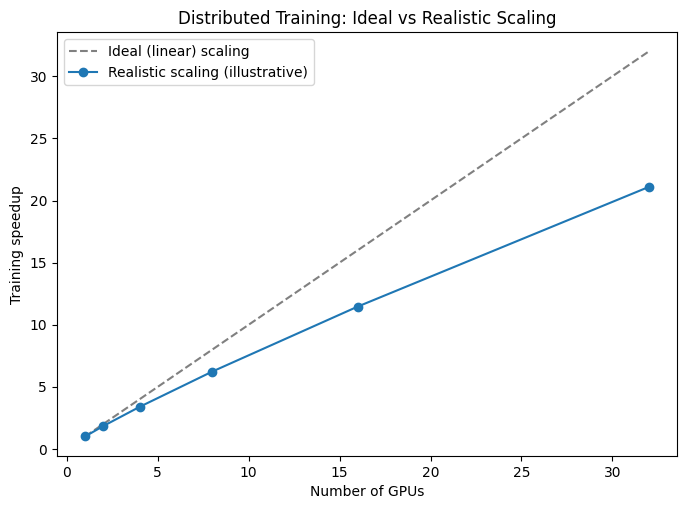

Scaling efficiency at each GPU count:
    1 GPUs: 100.0% efficiency
    2 GPUs: 92.0% efficiency
    4 GPUs: 84.6% efficiency
    8 GPUs: 77.9% efficiency
   16 GPUs: 71.6% efficiency
   32 GPUs: 65.9% efficiency


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

num_gpus = np.array([1, 2, 4, 8, 16, 32])
ideal_speedup = num_gpus
realistic_speedup = num_gpus * (0.92 ** np.log2(num_gpus))   # illustrative diminishing-efficiency model

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(num_gpus, ideal_speedup, "--", label="Ideal (linear) scaling", color="gray")
ax.plot(num_gpus, realistic_speedup, marker="o", label="Realistic scaling (illustrative)", color="tab:blue")
ax.set_xlabel("Number of GPUs")
ax.set_ylabel("Training speedup")
ax.set_title("Distributed Training: Ideal vs Realistic Scaling")
ax.legend()
plt.show()

print("Scaling efficiency at each GPU count:")
for n, speedup in zip(num_gpus, realistic_speedup):
    print(f"  {n:>3} GPUs: {speedup/n:.1%} efficiency")


### Interpretation
The gap between the ideal (dashed) and realistic (solid) curves — and how that gap **widens** as GPU count grows — is the direct, visual consequence of communication overhead's cumulative impact. This is precisely why distributed training system design (interconnect hardware choice, batch size tuning, sometimes more sophisticated gradient compression/communication-overlap techniques beyond this course's current scope) is a genuine engineering discipline in its own right at serious scale, not simply "add more GPUs and expect proportional speedup."

### Common Mistakes
- Assuming adding GPUs always provides proportional speedup — ignoring communication overhead's real, measurable impact, especially at larger GPU counts or with slower interconnects.
- Using a small per-GPU batch size when scaling to many GPUs — worsens the computation-to-communication ratio, directly hurting scaling efficiency beyond what's necessary.
- Not considering interconnect quality (NVLink within a machine vs. standard networking across machines) when planning or budgeting for a distributed training setup — often the single biggest real-world factor in achieved scaling efficiency.

### Interview Insight
**Q: Your team doubles the number of GPUs used for training but observes only a 1.6x speedup, not 2x. What factors would you investigate?**
A: This is expected to some degree — perfectly linear scaling is rarely achieved in practice due to communication overhead from synchronizing gradients across GPUs on every training step. I'd first check the interconnect: are the new GPUs on the same machine (fast NVLink) or spread across separate machines (slower standard networking)? I'd also check whether per-GPU batch size was kept the same or reduced when doubling GPU count — a smaller per-GPU batch worsens the ratio of useful computation to communication overhead per step. Finally, I'd consider whether the model itself is large enough that gradient communication volume is a significant fraction of total step time, which naturally becomes more pronounced as more devices participate in the synchronization.

### Quiz (Chapter 70)
1. Define scaling efficiency, and explain why it's rarely exactly 100%.
2. Why does a larger per-GPU batch size improve scaling efficiency?
3. Why does interconnect speed (NVLink vs. standard networking) matter so much for distributed training performance?


---
# CHAPTER 71 — GRADIENT ACCUMULATION

## 1. Concept
Gradient accumulation simulates a **larger effective batch size** than would otherwise fit in available GPU memory, by accumulating (summing) gradients across several smaller "micro-batches" **before** calling `optimizer.step()` — directly solving Chapter 33's CUDA OOM problem without requiring multiple GPUs at all, a single-GPU-friendly alternative/complement to Chapter 69-70's distributed approaches.

## 2. The Core Mechanism


In [ ]:
import torch
import torch.nn as nn

model = nn.Linear(20, 2)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

accumulation_steps = 4   # simulate a batch size 4x LARGER than what actually fits in memory at once

micro_batches = [
    (torch.randn(8, 20), torch.randint(0, 2, (8,)))   # a SMALL micro-batch of size 8
    for _ in range(accumulation_steps)
]   # 4 micro-batches of 8 = an EFFECTIVE batch size of 32, without ever holding 32 samples' activations at once

optimizer.zero_grad()   # zero ONCE, before the WHOLE accumulation cycle -- NOT per micro-batch

for i, (X_micro, y_micro) in enumerate(micro_batches):
    logits = model(X_micro)
    loss = criterion(logits, y_micro)

    # CRITICAL: divide the loss by accumulation_steps BEFORE backward() --
    # this ensures the ACCUMULATED gradient ends up correctly averaged,
    # matching what a single, genuinely-large batch's gradient would have been
    loss = loss / accumulation_steps
    loss.backward()   # gradients ACCUMULATE here (Chapter 15's default accumulation behavior,
                         # now used DELIBERATELY rather than being a bug to avoid)

    print(f"Micro-batch {i}: scaled loss = {loss.item():.4f}")

optimizer.step()   # apply the update ONLY after ALL micro-batches' gradients have accumulated
print("\nOptimizer step applied -- using the gradient ACCUMULATED across all 4 micro-batches,")
print("mathematically equivalent to having processed one genuine batch of 32 samples at once.")


Micro-batch 0: scaled loss = 0.1764
Micro-batch 1: scaled loss = 0.1784
Micro-batch 2: scaled loss = 0.1745
Micro-batch 3: scaled loss = 0.2164

Optimizer step applied -- using the gradient ACCUMULATED across all 4 micro-batches,
mathematically equivalent to having processed one genuine batch of 32 samples at once.


### Line-by-Line Explanation — Why Each Piece Matters
- `optimizer.zero_grad()` happens **once**, before the entire accumulation cycle begins — not inside the micro-batch loop — this is the precise, deliberate repurposing of Chapter 15's "gradients accumulate by default unless explicitly zeroed" behavior: here, that accumulation is exactly the desired behavior, not a bug to defend against.
- `loss = loss / accumulation_steps` — **essential** for mathematical correctness: without this division, the accumulated gradient would be the **sum** of 4 micro-batches' gradients, which is proportionally 4x larger than what a genuine single batch of that combined size would have produced (since a standard batch's loss is a mean, not a sum, over its samples) — dividing each micro-batch's loss by `accumulation_steps` before `backward()` ensures the final accumulated gradient correctly represents the **average** gradient over the full effective batch, matching what training with a genuinely larger batch size would have produced.
- `optimizer.step()` is called only **once**, after the full accumulation loop — applying one parameter update based on the combined, correctly-scaled gradient from all 4 micro-batches together.

## 3. Memory Savings, Quantified


In [ ]:
print("""
WITHOUT gradient accumulation, processing a batch of 32 requires holding ALL 32
samples' activations in memory SIMULTANEOUSLY (for the backward pass, Chapter 14).

WITH gradient accumulation (4 micro-batches of 8), AT ANY GIVEN MOMENT, only ONE
micro-batch's 8 samples' activations need to be held in memory -- the memory
footprint is governed by the MICRO-batch size, not the EFFECTIVE batch size.

This is EXACTLY why gradient accumulation is one of the most common, practical
techniques for training with an effectively large batch size on memory-
constrained hardware (a single consumer GPU, or even just a smaller/cheaper
cloud instance) -- directly complementing (and often used TOGETHER with)
mixed precision (Chapter 29) and the memory-optimization techniques Chapter 75
covers in more depth.

TRADEOFF: gradient accumulation trades MEMORY for TIME -- 4 micro-batch forward/
backward passes take roughly the SAME total compute time as 1 larger batch would
have, so accumulation does NOT provide a speed benefit the way adding more GPUs
(Chapter 69-70) does -- it specifically solves the MEMORY constraint, not the
SPEED constraint.
""")



WITHOUT gradient accumulation, processing a batch of 32 requires holding ALL 32
samples' activations in memory SIMULTANEOUSLY (for the backward pass, Chapter 14).

WITH gradient accumulation (4 micro-batches of 8), AT ANY GIVEN MOMENT, only ONE
micro-batch's 8 samples' activations need to be held in memory -- the memory
footprint is governed by the MICRO-batch size, not the EFFECTIVE batch size.

This is EXACTLY why gradient accumulation is one of the most common, practical
techniques for training with an effectively large batch size on memory-
constrained hardware (a single consumer GPU, or even just a smaller/cheaper
cloud instance) -- directly complementing (and often used TOGETHER with)
mixed precision (Chapter 29) and the memory-optimization techniques Chapter 75
covers in more depth.

TRADEOFF: gradient accumulation trades MEMORY for TIME -- 4 micro-batch forward/
backward passes take roughly the SAME total compute time as 1 larger batch would
have, so accumulation does NOT prov

### Common Mistakes
- Forgetting to divide the loss by `accumulation_steps` — produces a gradient that's too large by exactly that factor, effectively training with an unintentionally much larger learning rate than configured, a subtle, damaging training-quality bug.
- Calling `optimizer.zero_grad()` inside the micro-batch loop instead of once before it — defeats the entire purpose, since each micro-batch's gradient would simply overwrite the previous one rather than accumulating.
- Calling `optimizer.step()` after every micro-batch instead of once after the full accumulation cycle — applies 4 separate, smaller updates instead of 1 correctly-combined larger one, not actually achieving the intended larger effective batch size's training dynamics.
- Expecting gradient accumulation to provide a training-speed benefit — it solves a memory constraint, not a speed constraint; total compute time remains roughly the same (or very slightly worse, due to accumulation's minor overhead) compared to a hypothetical single large batch.

### Interview Insight
**Q: Why must you divide the loss by `accumulation_steps` before calling `.backward()` in gradient accumulation, and what happens if you forget this?**
A: A standard batch's loss (from `CrossEntropyLoss` and most PyTorch loss functions by default) is the **mean** loss across that batch's samples, not the sum — so a genuine single batch of 32 samples produces a gradient reflecting that averaged loss. If you accumulate 4 micro-batches of 8 each without dividing, you're effectively summing 4 independently-averaged losses' gradients together, producing a combined gradient that's proportionally larger (specifically, about `accumulation_steps` times larger) than what a true batch of 32 would have produced. Without correcting for this via dividing each micro-batch's loss by `accumulation_steps` before `.backward()`, the resulting update is effectively equivalent to training with a learning rate `accumulation_steps` times larger than configured — a subtle, easy-to-introduce bug that can meaningfully destabilize or distort training, without raising any error to flag that something is wrong.

### Exercise
Implement a complete gradient accumulation training step for `accumulation_steps=8`, and verify (by comparing the final accumulated gradient's magnitude, conceptually) that the result would match training on one genuine batch of the full combined size.

### Quiz (Chapter 71)
1. Walk through the complete gradient accumulation pattern: where does `zero_grad()` go, where does `step()` go, and why?
2. Why must the loss be divided by `accumulation_steps` before `.backward()`?
3. Does gradient accumulation save training time, memory, both, or neither? Explain precisely.
4. How does gradient accumulation relate to Chapter 69's distributed data parallelism — are they solving the same problem?

### Chapter 71 Summary
- Gradient accumulation simulates a larger effective batch size on memory-constrained hardware by accumulating gradients across several smaller micro-batches before one combined optimizer step.
- Correctly scaling the loss (dividing by `accumulation_steps`) is essential for the accumulated gradient to mathematically match what a genuine larger batch would have produced.
- This technique trades time for memory, complementing (not replacing) the speed benefits of true multi-GPU data parallelism (Chapters 69-70).

---

## END OF NOTEBOOK 12 — What You Should Now Be Able To Do
- Monitor a production PyTorch model's prediction drift, latency percentiles, and GPU memory trends, and explain why percentile (not average) latency monitoring matters.
- Design and implement a statistically sound, consistent A/B test for comparing model versions in live production.
- Explain edge and mobile deployment's distinct constraints (compute, memory, power, connectivity) and assemble the quantization/export pipeline appropriate for each.
- Explain data vs. model parallelism, implement `DistributedDataParallel` training, and reason about real-world scaling efficiency and its limiting factors.
- Implement gradient accumulation correctly (including the critical loss-scaling step) to train with an effectively larger batch size on memory-constrained hardware.

## Before Moving to Notebook 13 (Chapters 72–78: Model Checkpointing, Custom Training Architectures, Custom Autograd, PyTorch 2.x Compilation, Performance Profiling, Memory Optimization, Gradient Clipping)
 